# 1. Looking at the MetroPT-3 data

Before we model anything we want to know what we are working with: how much data
there is, how often it is sampled, and whether the four reported failures are
visible at all.

The dataset is sensor data from the air compressor on a Porto metro train. The
documentation reports four air leaks, but there is no label column in the file.

In [1]:
import zipfile

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

DATA = '../data/metropt3.zip'

## Loading

The zip contains a single CSV, so pandas can read it directly.

In [2]:
with zipfile.ZipFile(DATA) as z:
    name = [n for n in z.namelist() if n.endswith('.csv')][0]
    with z.open(name) as f:
        data = pd.read_csv(f)

data['timestamp'] = pd.to_datetime(data['timestamp'])
data = data.sort_values('timestamp').set_index('timestamp')

print(f'{len(data):,} rows, {data.shape[1]} columns')
data.head()

1,516,948 rows, 16 columns


,Unnamed: 0,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
timestamp,,,,,,,,,,,,,,,,
2020-02-01 00:00:00,0,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:10,10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:19,20,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:29,30,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:39,40,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


## How often is it sampled?

The UCI page is ambiguous about this, so we check.

In [3]:
step = data.index.to_series().diff().dt.total_seconds()

print(f'from {data.index.min()} to {data.index.max()}')
print(f'that is {(data.index.max() - data.index.min()).days} days')
print(f'median gap between rows: {step.median():.0f} seconds')

from 2020-02-01 00:00:00 to 2020-09-01 03:59:50
that is 213 days
median gap between rows: 10 seconds


One reading every 10 seconds, not every second as one part of the documentation
suggests.

## Picking a resolution

Ten seconds is finer than we need. An air leak develops over hours, so readings
ten seconds apart are almost identical and only slow us down.

We aggregate to **10-minute means**. Two reasons:

1. It leaves about 30 000 rows, roughly the size of the taxi series from block 1,
   which we know is a workable size.
2. The Kelmarsh wind turbine data we use later is already at 10 minutes, so the
   same code will run on both datasets.

We keep the seven analogue sensors. The eight digital ones are on/off signals,
which do not average meaningfully.

In [4]:
sensors = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs',
           'Oil_temperature', 'Motor_current']

res = data[sensors].resample('10min').mean()

print(f'{len(res):,} rows after aggregation')
res.head()

30,696 rows after aggregation


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current
timestamp,,,,,,,
2020-02-01 00:00:00,-0.013016,9.053705,9.038230,-0.022787,9.054393,53.038934,0.040000
2020-02-01 00:10:00,-0.013836,8.480361,8.466590,-0.023180,8.480918,51.387295,0.039590
2020-02-01 00:20:00,1.570033,9.169833,7.626233,-0.022967,9.169300,51.415000,3.095708
2020-02-01 00:30:00,-0.012820,9.300000,9.284262,-0.022656,9.300918,53.131148,0.727828
2020-02-01 00:40:00,-0.013833,8.703833,8.689200,-0.023167,8.704767,52.008333,0.039833


## The four reported failures

These dates come from the dataset documentation, where the operator reported air
leaks. They are periods, not exact moments, and that imprecision is something we
will have to deal with later.

In [5]:
failures = [
    ('F1', '2020-04-18', '2020-04-18'),
    ('F2', '2020-05-29', '2020-05-30'),
    ('F3', '2020-06-05', '2020-06-07'),
    ('F4', '2020-07-15', '2020-07-15'),
]


def mark_failures(ax):
    '''Shade the reported failure periods on a plot.'''
    for _, start, end in failures:
        ax.axvspan(pd.Timestamp(start),
                   pd.Timestamp(end) + pd.Timedelta(days=1),
                   color='sandybrown', alpha=0.5)

## Does anything stand out?

We plot every sensor across the whole period, with the reported failures shaded.

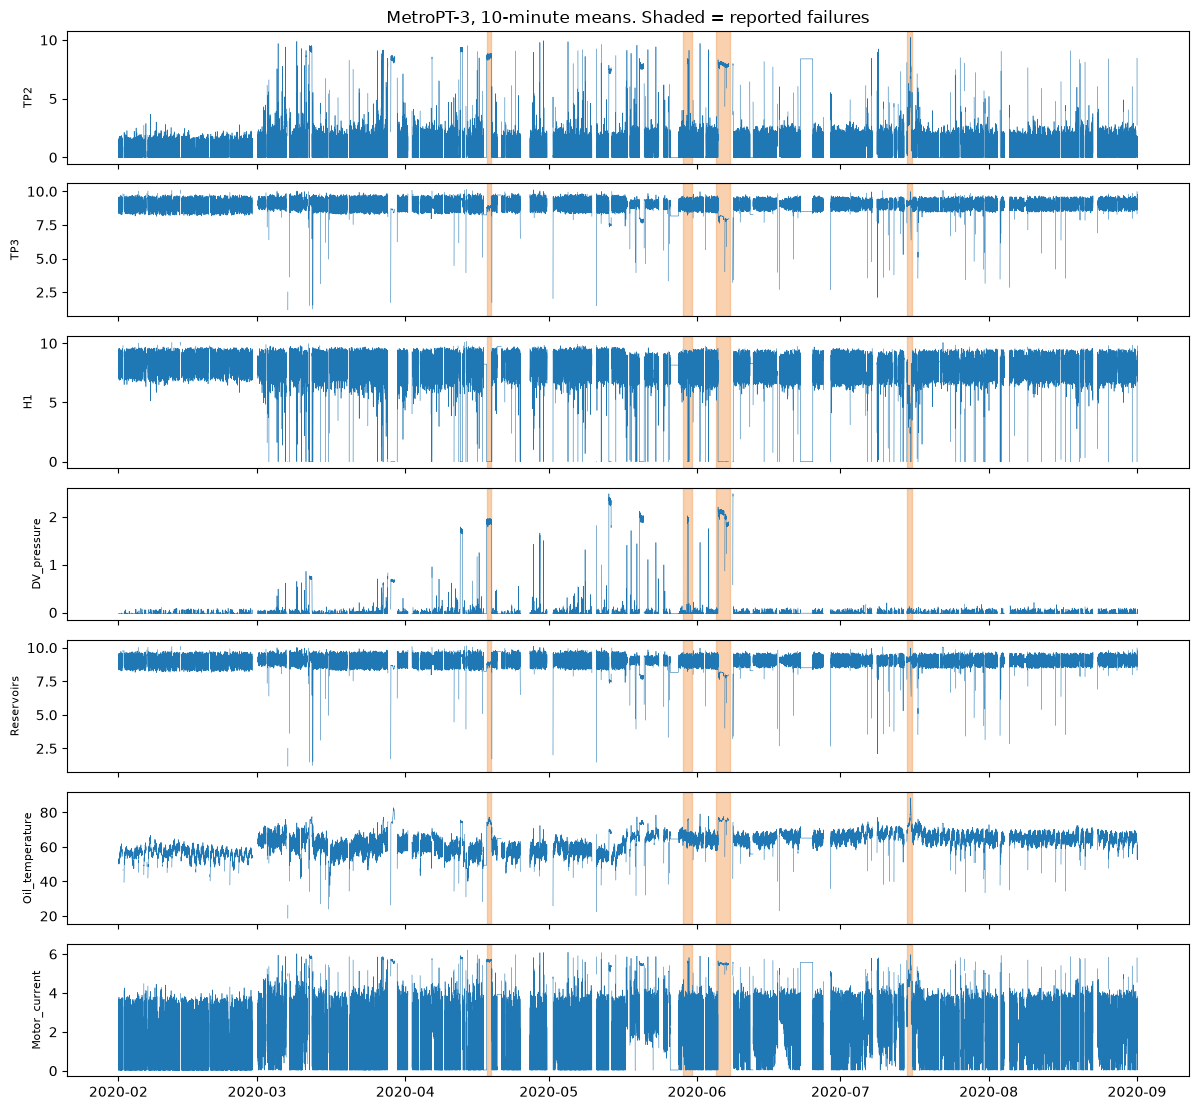

In [6]:
fig, axes = plt.subplots(len(sensors), 1, figsize=(12, 1.6 * len(sensors)),
                         sharex=True)

for ax, name in zip(axes, sensors):
    ax.plot(res.index, res[name], lw=0.4)
    ax.set_ylabel(name, fontsize=8)
    mark_failures(ax)

axes[0].set_title('MetroPT-3, 10-minute means. Shaded = reported failures')
plt.tight_layout()

`DV_pressure` is the one to watch. It sits at zero for most of February, then
starts producing spikes that grow through spring, and three of the four shaded
periods line up with a sustained high plateau rather than a brief spike.

Two things are already worth noting:

- There are spikes as large as the failures **outside** the shaded periods.
- February looks different from the rest of the series. Something about the
  operation changes around 1 March.

## A closer look at each failure

We compare each sensor against how it behaved in February, measured in standard
deviations. That is not a model, just a way of putting sensors with different
units on the same axis.

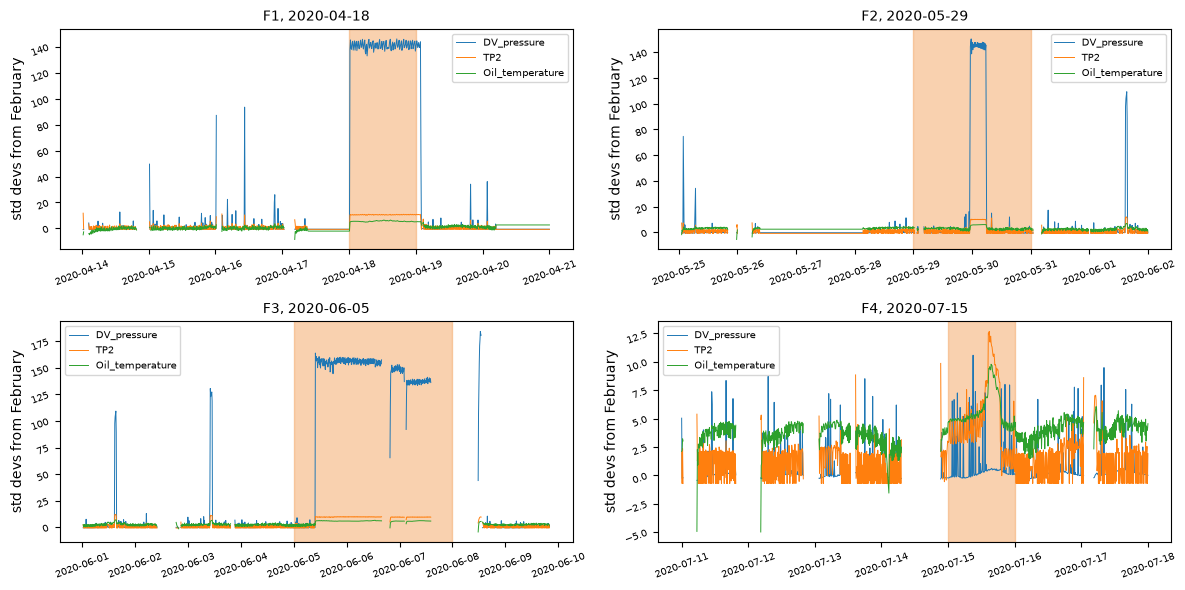

In [7]:
baseline = res.loc[:'2020-02-29']
z = (res - baseline.mean()) / baseline.std()

fig, axes = plt.subplots(2, 2, figsize=(12, 6))

for ax, (label, start, end) in zip(axes.ravel(), failures):
    start, end = pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1)
    window = z.loc[start - pd.Timedelta(days=4): end + pd.Timedelta(days=2)]

    for name in ['DV_pressure', 'TP2', 'Oil_temperature']:
        ax.plot(window.index, window[name], lw=0.7, label=name)

    ax.axvspan(start, end, color='sandybrown', alpha=0.5)
    ax.set_title(f'{label}, {start.date()}', fontsize=10)
    ax.set_ylabel('std devs from February')
    ax.tick_params(labelsize=7, rotation=20)
    ax.legend(fontsize=7)

plt.tight_layout()

## Why the numbers are so large

The y-axis reaches 140 standard deviations, which looks absurd until you see why.
`DV_pressure` sits at almost exactly zero for the whole of February, so its standard
deviation in the baseline is tiny, and dividing by a tiny number gives a huge result.

So read the **shape**, not the magnitude: a flat line that jumps to a plateau and
stays there. If we use a baseline like this in the actual detector we will need
something more robust, and that is noted in `DECISIONS.md`.

## What we learned

**Three of the four failures look the same.** F1, F2 and F3 all show `DV_pressure`
jumping to a plateau far above normal and staying there for hours. That is a clear
signal and we should be able to detect it.

**The fourth one does not.** F4 in July shows nothing in `DV_pressure`. Only the
oil temperature rises, slowly, and then falls back. Either it is a different kind
of fault, or the reported date does not match what the sensors saw.

**There are warnings beforehand.** Shorter `DV_pressure` spikes appear a day or two
before F1 and F3. If a detector reacts to those, we have actual early warning
rather than hindsight. That is the interesting part of the project.

## Next

Notebook 2: build sliding-window features and fit a KDE on normal operation.

Open questions go in `DECISIONS.md` rather than here, so we do not lose them.